# 分類器 6 種を同じデータで比較

**出典**　機械学習 4 分野の教科書 — 第 3 章 1-B 分類 ／ 07 手法の比較と選び方

**このノートのパス**　`ml-code/03_classification/02_classifier_comparison.ipynb`

**このノートで確かめること**
三日月形の非線形データに 6 つの分類器を当て、**直線しか引けない手法がはっきり劣る**ことを見る。
決定境界の形とデータの形が合っているかを確かめるのが要点。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `scikit-learn, numpy, matplotlib` |
| 実行時間の目安 | 約 20 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q scikit-learn numpy matplotlib

In [3]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

X, y = make_moons(n_samples=500, noise=0.25, random_state=0)  # 三日月形の非線形データ

models = {
    "ロジスティック回帰": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "kNN (k=5)":        make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "SVM (linear)":     make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "SVM (RBF)":        make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma="scale")),
    "決定木 (depth=4)":  DecisionTreeClassifier(max_depth=4, random_state=0),
    "ナイーブベイズ":     GaussianNB(),
}

for name, m in models.items():
    s = cross_val_score(m, X, y, cv=5, scoring="accuracy")
    print(f"{name:>18}: {s.mean():.3f} ± {s.std():.3f}")

         ロジスティック回帰: 0.856 ± 0.039
         kNN (k=5): 0.920 ± 0.013
      SVM (linear): 0.856 ± 0.038
         SVM (RBF): 0.926 ± 0.008
     決定木 (depth=4): 0.890 ± 0.035
           ナイーブベイズ: 0.852 ± 0.030


### 決定境界を描いて、数字の理由を目で見る

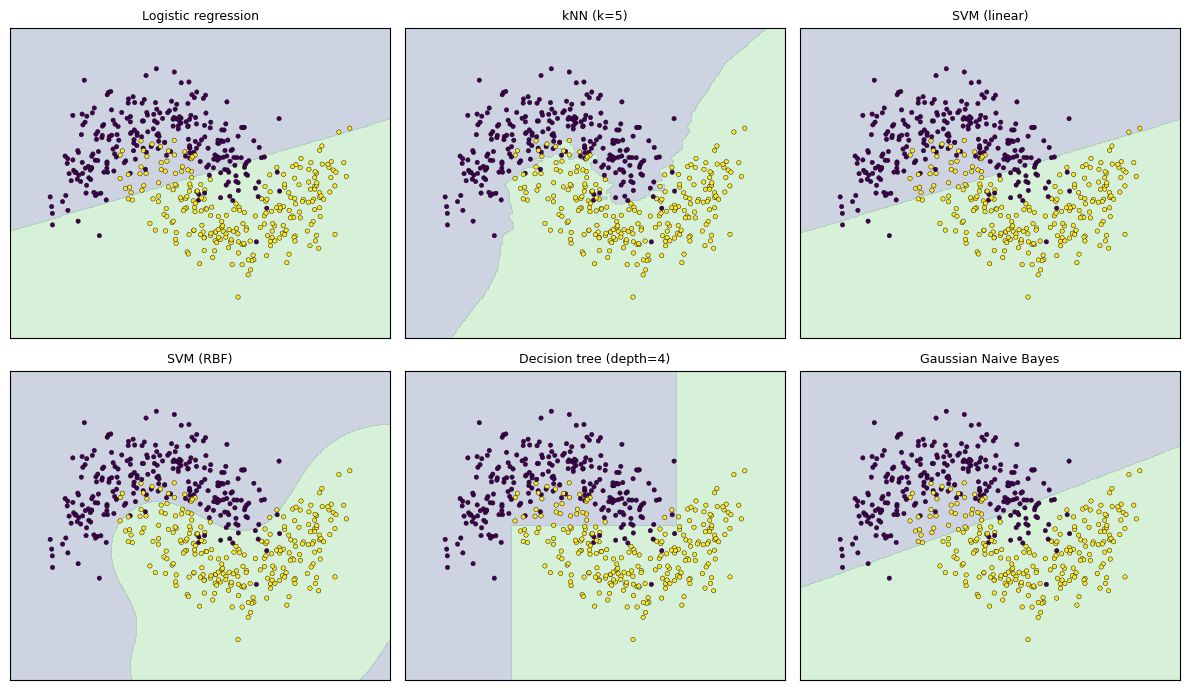

In [4]:
import numpy as np
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-.5, X[:, 0].max()+.5, 300),
                     np.linspace(X[:, 1].min()-.5, X[:, 1].max()+.5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

# 図の見出しは英語にし、日本語フォント未導入の環境でも文字化けを防ぐ
plot_titles = ["Logistic regression", "kNN (k=5)", "SVM (linear)",
               "SVM (RBF)", "Decision tree (depth=4)", "Gaussian Naive Bayes"]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, m, title in zip(axes.ravel(), models.values(), plot_titles):
    m.fit(X, y)
    ax.contourf(xx, yy, m.predict(grid).reshape(xx.shape), alpha=.25, levels=1)
    ax.scatter(X[:, 0], X[:, 1], c=y, s=10, edgecolors="k", linewidths=.3)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 読み取りどころ

**三日月形データでは、直線しか引けない手法（ロジスティック回帰・線形 SVM）がはっきり劣る。**
境界の形と、データの形が合っているかを確かめるのが要点である。

⚠️ 日本語のタイトルが □ で表示される場合はフォントの問題。解析には影響しないが、気になるなら `japanize-matplotlib` を入れるか、名前を英語にする。

この比較は**固定のハイパーパラメータ**で行っている。本来はモデルごとに探索予算を揃えて比べるべきで、その手順は `01D_hpo/` にある。